# 01 - Download Dataset Panoptic Indoor Segmentation v5

Notebook ini:
1. Download dataset **Panoptic Indoor Segmentation v5** dari Roboflow (format COCO segmentation, opsional YOLO).
2. Menghitung **jumlah instance & jumlah gambar per kelas** di tiap split (train/valid/test).
3. Menampilkan contoh mask per kelas, supaya tahu objek apa yang perlu difoto untuk test set sendiri.

Sumber: https://universe.roboflow.com/panopticindoor/panoptic-indoor-segmentation/dataset/5 (CC BY 4.0)

**Butuh API key Roboflow** (gratis): login di roboflow.com → Settings → API Keys → copy *Private API Key*.
Jangan tulis key langsung di notebook. Di Colab simpan di *Secrets* (ikon kunci) dengan nama `ROBOFLOW_API_KEY`.

In [1]:
%pip install -q roboflow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os

def get_api_key():
    # 1) Colab Secrets
    try:
        from google.colab import userdata
        key = userdata.get("ROBOFLOW_API_KEY")
        if key:
            return key
    except Exception:
        pass
    # 2) Environment variable
    if os.environ.get("ROBOFLOW_API_KEY"):
        return os.environ["ROBOFLOW_API_KEY"]
    # 3) Ketik manual (tidak tersimpan di notebook)
    from getpass import getpass
    return getpass("Roboflow API key: ")

API_KEY = (get_api_key() or "").strip().strip('"').strip("'")
if not API_KEY:
    raise ValueError("API key kosong. Jalankan ulang cell ini dan paste key-nya, lalu tekan Enter.")
print(f"API key terbaca: {API_KEY[:3]}... ({len(API_KEY)} karakter)")

WORKSPACE = "panopticindoor"
PROJECT   = "panoptic-indoor-segmentation"
VERSION   = 5
DATA_ROOT = "data"

API key terbaca: ejF... (20 karakter)


## Download format COCO segmentation

Format COCO cocok untuk Mask R-CNN (Detectron2 / torchvision / MMDetection) dan juga untuk analisis kelas di bawah.

In [3]:
from roboflow import Roboflow

rf = Roboflow(api_key=API_KEY)
version = rf.workspace(WORKSPACE).project(PROJECT).version(VERSION)

coco_dir = os.path.join(DATA_ROOT, f"panoptic-indoor-v{VERSION}-coco")
ds_coco = version.download("coco-segmentation", location=coco_dir, overwrite=False)
print("Lokasi:", ds_coco.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to data\panoptic-indoor-v5-coco in coco-segmentation:: 100%|██████████| 930/930 [00:00<00:00, 1351.90it/s]


Lokasi: c:\Users\Royan\Documents\Semester 5\comvis\data\panoptic-indoor-v5-coco


## (Opsional) Download format YOLO segmentation

Untuk model keluarga YOLO (Ultralytics YOLOv8/YOLO11-seg). Lewati kalau belum perlu.

In [4]:
DOWNLOAD_YOLO = False

if DOWNLOAD_YOLO:
    yolo_dir = os.path.join(DATA_ROOT, f"panoptic-indoor-v{VERSION}-yolo")
    ds_yolo = version.download("yolov8", location=yolo_dir, overwrite=False)
    print("Lokasi:", ds_yolo.location)

## Statistik per kelas

Catatan: export COCO dari Roboflow biasanya punya satu kategori "induk" (nama project) yang tidak dipakai anotasi.
Kategori yang jumlah anotasinya 0 di semua split ditandai, karena daftar 93 kelas di halaman project mencakup kelas typo
(mis. `ligjt`, `cuo`, `spoom`) yang bisa jadi tidak ada / sangat sedikit di v5.

In [5]:
import json
from collections import Counter, defaultdict
import pandas as pd

SPLITS = ["train", "valid", "test"]
coco = {}
for split in SPLITS:
    path = os.path.join(ds_coco.location, split, "_annotations.coco.json")
    with open(path, encoding="utf-8") as f:
        coco[split] = json.load(f)
    print(f"{split:5s}: {len(coco[split]['images']):4d} gambar, {len(coco[split]['annotations']):6d} anotasi")

# Nama kategori (diasumsikan sama di semua split, tapi digabung untuk aman)
cat_names = {}
for split in SPLITS:
    for c in coco[split]["categories"]:
        cat_names[c["id"]] = c["name"]

rows = []
for split in SPLITS:
    inst = Counter(a["category_id"] for a in coco[split]["annotations"])
    imgs = defaultdict(set)
    for a in coco[split]["annotations"]:
        imgs[a["category_id"]].add(a["image_id"])
    for cid, name in cat_names.items():
        rows.append({"class": name, "split": split, "instances": inst.get(cid, 0), "images": len(imgs.get(cid, ()))})

long = pd.DataFrame(rows)
stats = long.pivot_table(index="class", columns="split", values=["instances", "images"], aggfunc="sum", fill_value=0)
stats.columns = [f"{v}_{s}" for v, s in stats.columns]
stats["instances_total"] = sum(stats[f"instances_{s}"] for s in SPLITS)
stats["images_total"] = sum(stats[f"images_{s}"] for s in SPLITS)
stats = stats.sort_values("instances_total", ascending=False)

print("Total kategori di file COCO:", len(cat_names))
print("Kategori dengan >=1 anotasi:", (stats["instances_total"] > 0).sum())
pd.set_option("display.max_rows", 200)
stats

train:  397 gambar,   4479 anotasi
valid:  166 gambar,   2022 anotasi
test :  359 gambar,   5344 anotasi
Total kategori di file COCO: 75
Kategori dengan >=1 anotasi: 74


,images_test,images_train,images_valid,instances_test,instances_train,instances_valid,instances_total,images_total
class,,,,,,,,
wall-other-merged,266,252,100,650,756,315,1721,618
table-merged,123,150,54,258,319,134,711,327
person,84,98,49,413,192,90,695,231
chair,114,50,16,353,217,67,637,180
floor-other-merged,130,135,43,239,261,92,592,308
book,36,23,10,349,105,15,469,69
food-other-merged,38,54,27,149,127,108,384,119
light,98,19,9,295,41,24,360,126
pan,21,76,30,34,225,91,350,127


In [6]:
# Kelas yang tidak punya anotasi sama sekali / sangat jarang
print("Tanpa anotasi:", stats.index[stats["instances_total"] == 0].tolist())
print()
print("Jarang (<10 instance total):")
print(stats.loc[(stats["instances_total"] > 0) & (stats["instances_total"] < 10), ["instances_total", "images_total"]])

Tanpa anotasi: ['indoor-objects']

Jarang (<10 instance total):
             instances_total  images_total
class                                     
mouse                      8             8
clock                      7             7
keyboard                   7             7
shelf                      6             4
wall-stone                 6             6
flower                     6             5
scissors                   6             3
teddy bear                 6             3
toaster                    5             5
wall                       2             1
hair drier                 2             2
scissor                    2             1
st-                        1             1
tree-merged                1             1


In [7]:
os.makedirs("outputs", exist_ok=True)
stats.to_csv("outputs/class_stats_v5.csv")
print("Disimpan ke outputs/class_stats_v5.csv")

Disimpan ke outputs/class_stats_v5.csv


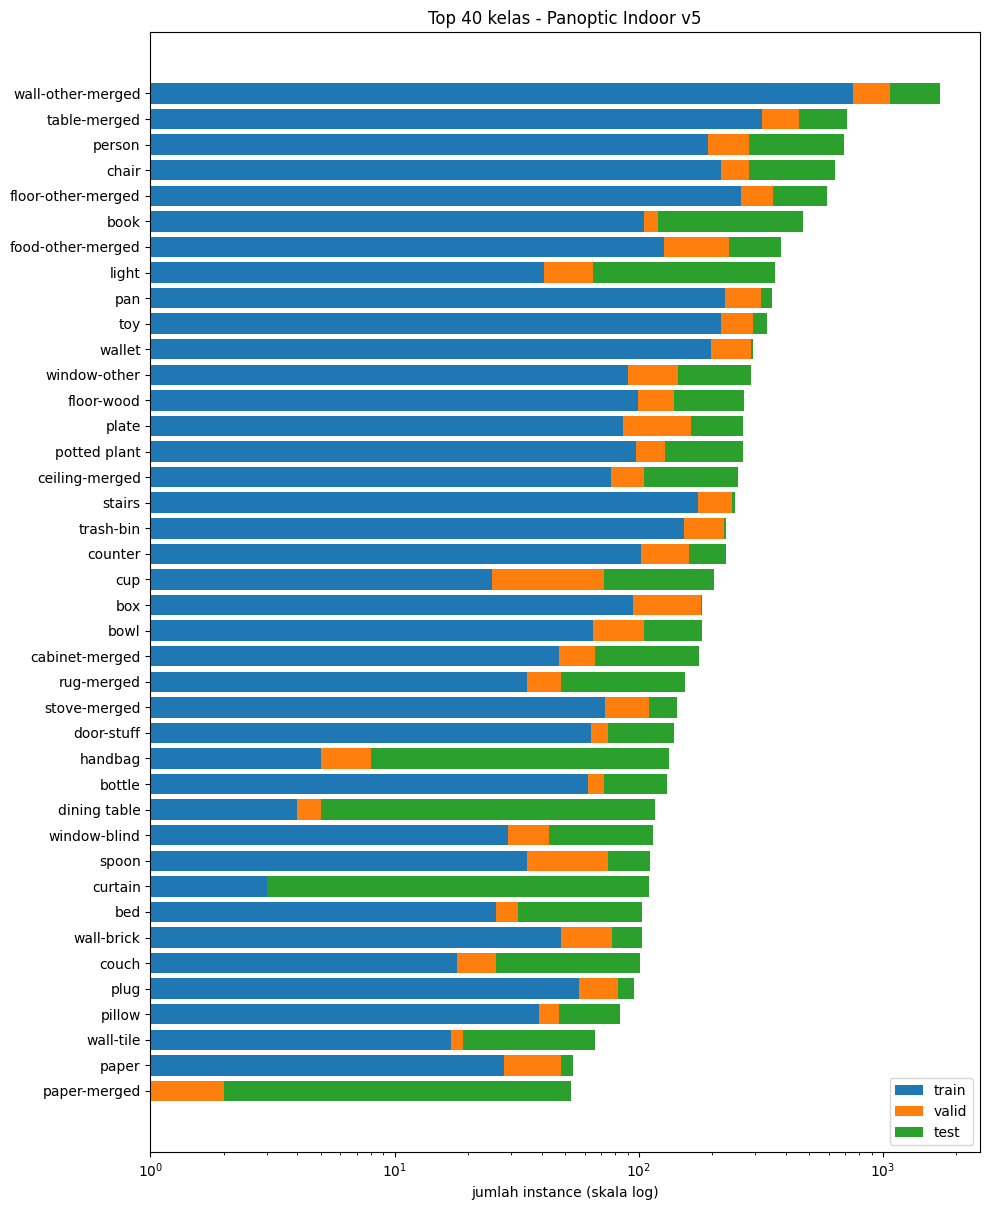

In [8]:
import matplotlib.pyplot as plt

TOP = 40
used = stats[stats["instances_total"] > 0].head(TOP)
fig, ax = plt.subplots(figsize=(10, 0.28 * len(used) + 1))
left = None
for split in SPLITS:
    vals = used[f"instances_{split}"].values
    ax.barh(used.index, vals, left=left, label=split)
    left = vals if left is None else left + vals
ax.invert_yaxis()
ax.set_xscale("log")
ax.set_xlabel("jumlah instance (skala log)")
ax.set_title(f"Top {TOP} kelas - Panoptic Indoor v{VERSION}")
ax.legend()
plt.tight_layout()
plt.show()

## Contoh mask per kelas

Menampilkan satu contoh gambar per kelas (dari split train) dengan mask kelas itu saja.
Gunakan ini untuk tahu seperti apa objek/area tiap kelas dianotasi (mis. `wall-other-merged` vs `wall-tile`).

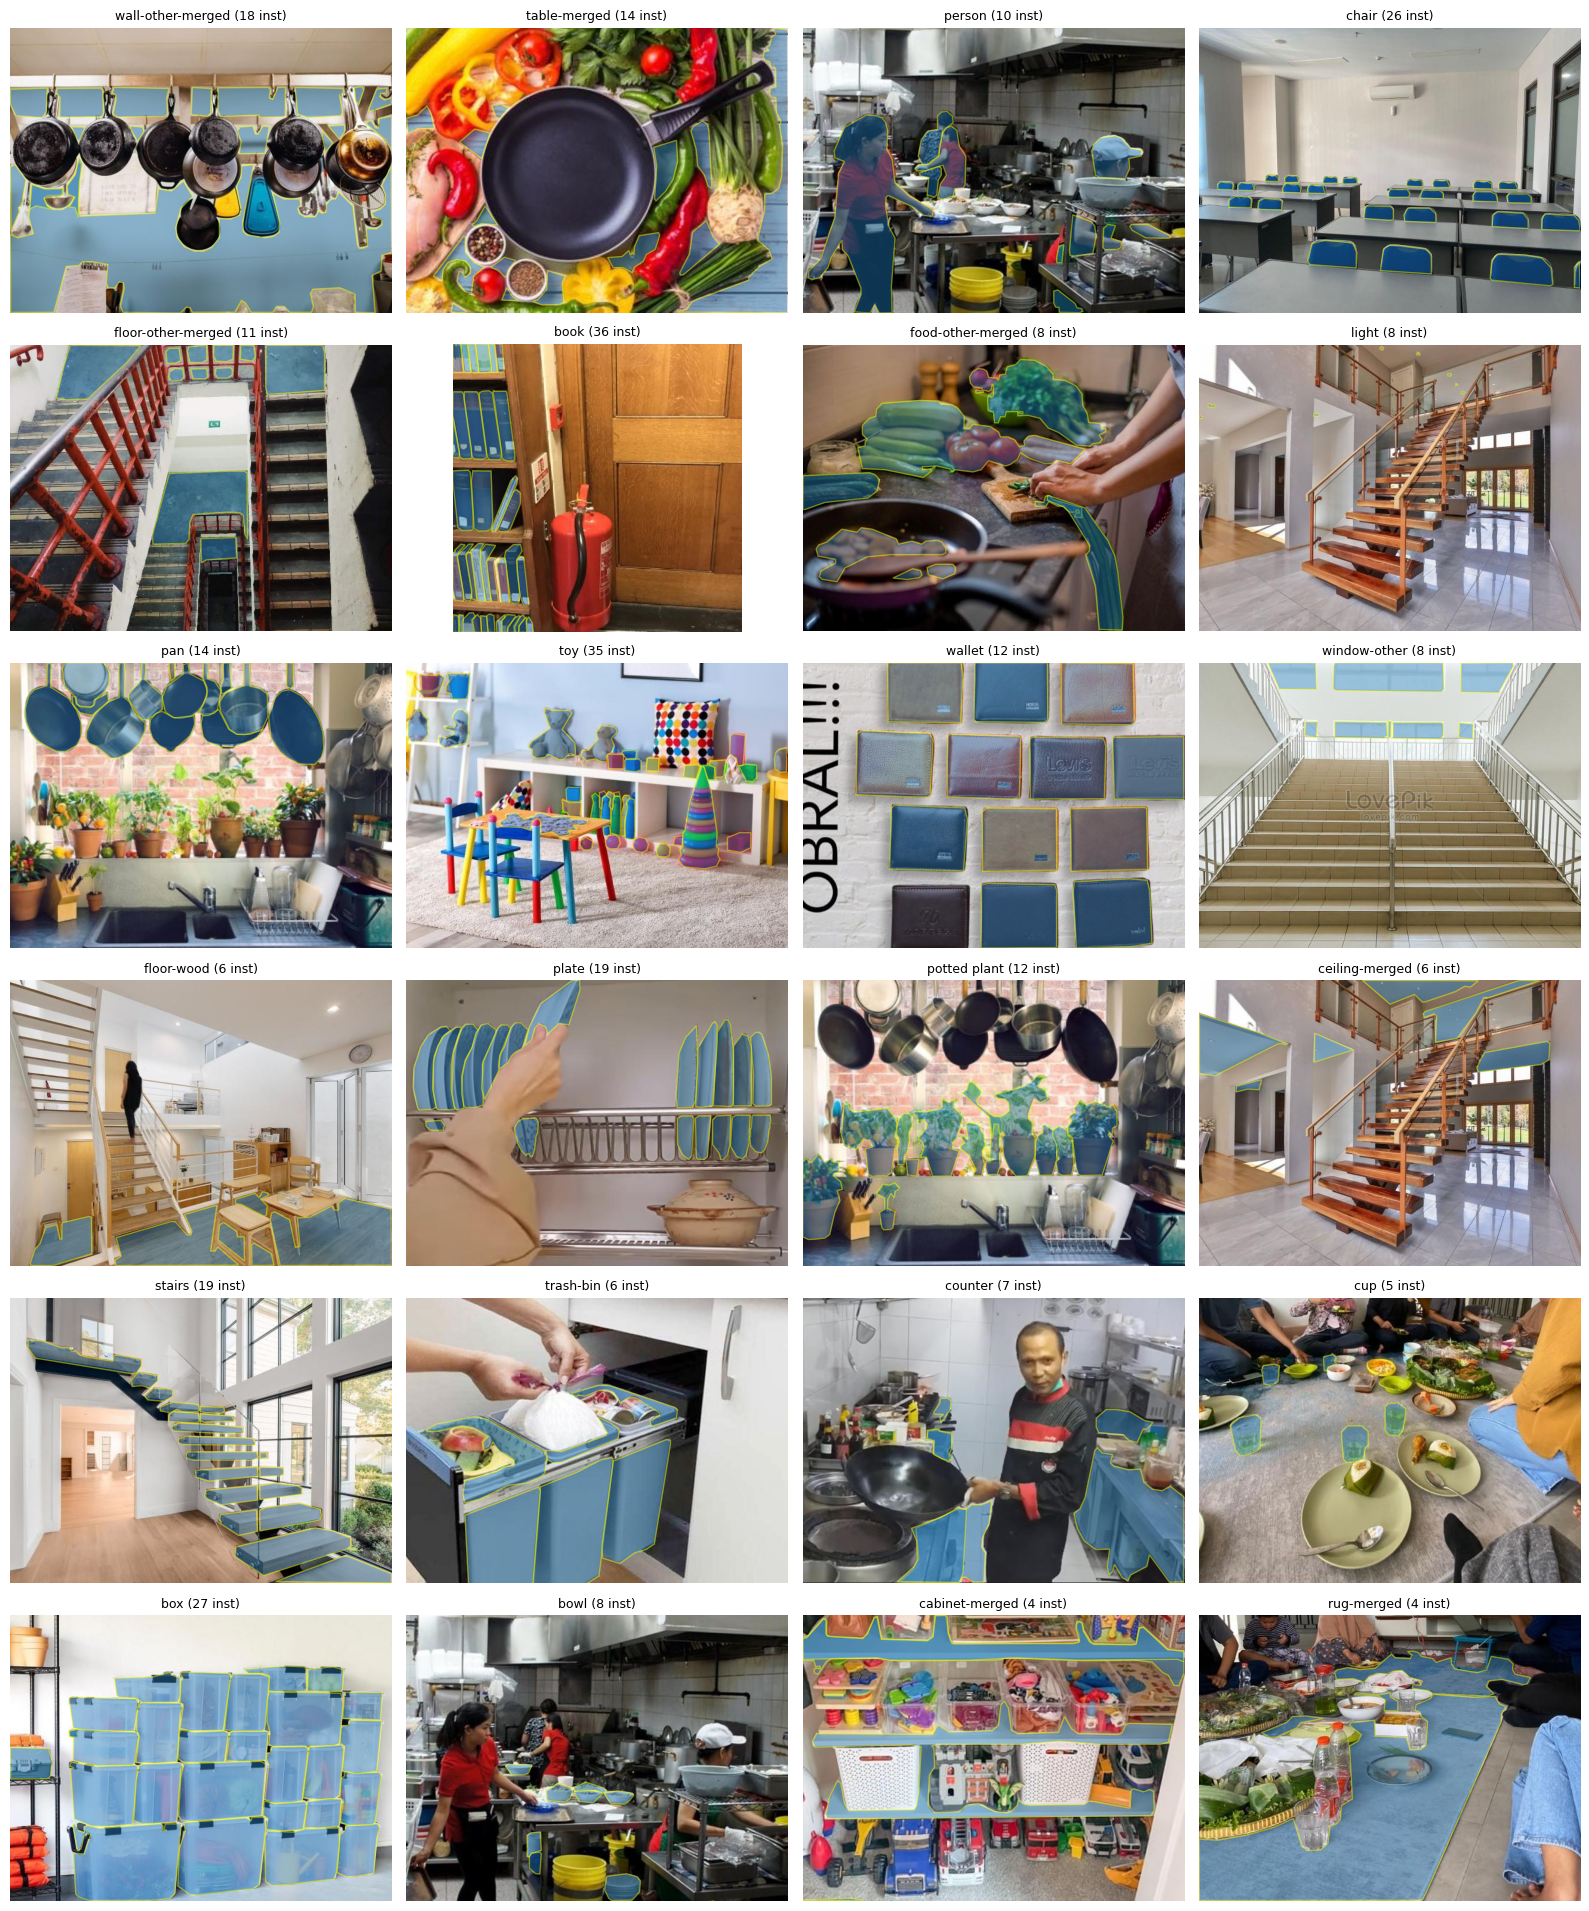

In [9]:
from PIL import Image
from matplotlib.patches import Polygon
import math

def show_class_examples(class_names, split="train", ncols=4):
    data = coco[split]
    name_to_id = {c["name"]: c["id"] for c in data["categories"]}
    img_by_id = {im["id"]: im for im in data["images"]}
    anns_by_img_cat = defaultdict(list)
    for a in data["annotations"]:
        anns_by_img_cat[(a["image_id"], a["category_id"])].append(a)

    n = len(class_names)
    nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
    axes = list(getattr(axes, "flat", [axes]))
    for ax, cname in zip(axes, class_names):
        ax.axis("off")
        cid = name_to_id.get(cname)
        # pilih gambar dengan instance terbanyak untuk kelas ini
        cands = [(len(v), k[0]) for k, v in anns_by_img_cat.items() if k[1] == cid]
        if not cands:
            ax.set_title(f"{cname}\n(tidak ada di {split})", fontsize=9)
            continue
        _, img_id = max(cands)
        im = img_by_id[img_id]
        img = Image.open(os.path.join(ds_coco.location, split, im["file_name"])).convert("RGB")
        ax.imshow(img)
        for a in anns_by_img_cat[(img_id, cid)]:
            seg = a.get("segmentation")
            if isinstance(seg, list):
                for poly in seg:
                    if len(poly) >= 6:
                        ax.add_patch(Polygon(list(zip(poly[0::2], poly[1::2])), closed=True,
                                             fill=True, alpha=0.45, edgecolor="yellow", linewidth=1))
        ax.set_title(f"{cname} ({len(anns_by_img_cat[(img_id, cid)])} inst)", fontsize=9)
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# 24 kelas terbanyak; ganti list ini untuk melihat kelas lain
show_class_examples(stats[stats["instances_total"] > 0].index[:24].tolist())

## Cek folder hasil download

In [10]:
for split in SPLITS:
    d = os.path.join(ds_coco.location, split)
    n_img = len([f for f in os.listdir(d) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{split:5s}: {n_img} file gambar di {d}")

train: 397 file gambar di c:\Users\Royan\Documents\Semester 5\comvis\data\panoptic-indoor-v5-coco\train
valid: 166 file gambar di c:\Users\Royan\Documents\Semester 5\comvis\data\panoptic-indoor-v5-coco\valid
test : 359 file gambar di c:\Users\Royan\Documents\Semester 5\comvis\data\panoptic-indoor-v5-coco\test
